# Projet final : les récoltes agricoles

**Équipe :** REJUSTE Jovens Fequiere, Herlentz Pierre, Bien aime Ronaldo, Deliscar Dave et Jerome Jethro.

**Répartition des analyses :** Bien aime Ronaldo (questions 1 et 2), Deliscar Dave (questions 3 et 4), Jerome Jethro (question 5). REJUSTE Jovens Fequiere réalise les jointures et indicateurs; Herlentz Pierre est responsable du diagnostic et du nettoyage.

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [2]:
print(f"Dimensions : {brut.shape[0]} lignes et {brut.shape[1]} colonnes")
display(brut.dtypes.to_frame("type"))
print("Valeurs manquantes par colonne :")
display(brut.isna().sum().to_frame("valeurs manquantes"))
print(f"Lignes dupliquees exactes : {brut.duplicated().sum()}")

for colonne in ["saison", "departement", "culture"]:
    valeurs = brut[colonne].value_counts(dropna=False).sort_index()
    print(f"\nValeurs observees dans {colonne} ({len(valeurs)} formes)")
    display(valeurs.to_frame("nombre de lignes"))

for colonne in ["surface_ha", "production_t"]:
    texte = brut[colonne].dropna().astype("string").str.strip()
    unites = texte.str.contains(r"(?:ha|t)$", case=False, regex=True)
    espaces = texte.str.contains(r"\s", regex=True)
    print(f"{colonne} : {unites.sum()} valeurs avec unite, {espaces.sum()} avec espaces de milliers.")

Dimensions : 408 lignes et 6 colonnes


,type
annee,int64
saison,str
departement,str
culture,str
surface_ha,str
production_t,str


Valeurs manquantes par colonne :


,valeurs manquantes
annee,0
saison,0
departement,0
culture,0
surface_ha,0
production_t,15


Lignes dupliquees exactes : 18

Valeurs observees dans saison (2 formes)


,nombre de lignes
saison,
Automne,204
Printemps,204



Valeurs observees dans departement (44 formes)


,nombre de lignes
departement,
Artibonite,3
Centre,2
Grand'Anse,4
Nord,2
Nord-Est,1
Nord-Ouest,3
Ouest,1
Sud,1
Sud-Est,1



Valeurs observees dans culture (33 formes)


,nombre de lignes
culture,
Banane,2
Haricot,2
Igname,2
Maïs,3
Pois congo,2
Riz,2
Sorgho,4
BANANE,1
Banane,57


surface_ha : 9 valeurs avec unite, 22 avec espaces de milliers.
production_t : 50 valeurs avec unite, 50 avec espaces de milliers.


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [3]:
propre = brut.drop_duplicates().copy()
print(f"Doublons exacts supprimes : {len(brut)} -> {len(propre)} lignes.")

for colonne in ["surface_ha", "production_t"]:
    propre[colonne] = (
        propre[colonne].astype("string").str.strip()
        .str.replace(r"\s*(?:ha|t)\s*$", "", regex=True, case=False)
        .str.replace(r"[\s,]", "", regex=True)
    )
    propre[colonne] = pd.to_numeric(propre[colonne], errors="coerce")

print("Valeurs manquantes apres conversion :")
display(propre.isna().sum().to_frame("valeurs manquantes"))
lignes_avant = len(propre)
propre = propre.dropna().copy()
print(f"Lignes incompletes supprimees : {lignes_avant} -> {len(propre)} lignes.")

cultures_reference = pd.read_csv("donnees/cultures.csv")
departements_reference = pd.read_csv("donnees/departements.csv")
pluies_reference = pd.read_csv("donnees/pluies.csv")
references = {
    "saison": pluies_reference["saison"].drop_duplicates(),
    "departement": departements_reference["departement"],
    "culture": cultures_reference["culture"],
}
for colonne, reference in references.items():
    correspondances = {valeur.casefold(): valeur for valeur in reference}
    normalisee = propre[colonne].astype("string").str.strip().str.casefold()
    propre[colonne] = normalisee.map(correspondances)
    if propre[colonne].isna().any():
        raise ValueError(f"Valeur sans correspondance dans {colonne}.")

assert propre.shape == (376, 6)
assert not propre.isna().any().any()
assert not propre.duplicated().any()
assert propre["saison"].nunique() == 2
assert propre["departement"].nunique() == 10
assert propre["culture"].nunique() == 7
print("Controle final :", propre.shape)
display(propre.head())
display(propre.describe(include="all").T)

Doublons exacts supprimes : 408 -> 390 lignes.
Valeurs manquantes apres conversion :


,valeurs manquantes
annee,0
saison,0
departement,0
culture,0
surface_ha,0
production_t,14


Lignes incompletes supprimees : 390 -> 376 lignes.
Controle final : (376, 6)


,annee,saison,departement,culture,surface_ha,production_t
0,2023,Printemps,Ouest,Maïs,1488,1327
1,2023,Printemps,Ouest,Sorgho,3577,2629
2,2023,Printemps,Ouest,Riz,2453,6122
4,2023,Printemps,Ouest,Haricot,814,464
5,2023,Printemps,Ouest,Pois congo,2436,1710


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
annee,376.0,NaN,NaN,NaN,2024.005319,0.816479,2023.0,2023.0,2024.0,2025.0,2025.0
saison,376,2,Automne,191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departement,376,10,Artibonite,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
culture,376,7,Banane,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
surface_ha,376.0,<NA>,<NA>,<NA>,1248.12766,874.6504,150.0,577.0,1038.5,1637.25,4065.0
production_t,376.0,<NA>,<NA>,<NA>,3515.308511,4565.075701,103.0,643.5,1486.5,4762.5,24133.0


## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [ ]:
# Partie 2 — Jointures et indicateurs réalisée par REJUSTE Jovens Fequiere.

cultures = pd.read_csv("donnees/cultures.csv")
pluies = pd.read_csv("donnees/pluies.csv")
departements = pd.read_csv("donnees/departements.csv")

# Chaque table de référence doit avoir une seule ligne par clé de jointure.
assert not cultures["culture"].duplicated().any()
assert not pluies.duplicated(["annee", "saison", "departement"]).any()
assert not departements["departement"].duplicated().any()

lignes_avant = len(propre)
complet = propre.merge(
    cultures,
    on="culture",
    how="left",
    validate="many_to_one",
    indicator="jointure_culture",
)
print(f"Jointure cultures : {lignes_avant} lignes avant, {len(complet)} après")
if not complet["jointure_culture"].eq("both").all():
    absentes = complet.loc[complet["jointure_culture"] != "both", "culture"].unique()
    raise ValueError(f"Cultures sans correspondance : {absentes.tolist()}")
complet = complet.drop(columns="jointure_culture")
assert len(complet) == lignes_avant

lignes_avant = len(complet)
complet = complet.merge(
    pluies,
    on=["annee", "saison", "departement"],
    how="left",
    validate="many_to_one",
    indicator="jointure_pluie",
)
print(f"Jointure pluies : {lignes_avant} lignes avant, {len(complet)} après")
if not complet["jointure_pluie"].eq("both").all():
    absentes = complet.loc[
        complet["jointure_pluie"] != "both",
        ["annee", "saison", "departement"],
    ].drop_duplicates()
    raise ValueError(f"Récoltes sans mesure de pluie :\n{absentes}")
complet = complet.drop(columns="jointure_pluie")
assert len(complet) == lignes_avant

lignes_avant = len(complet)
complet = complet.merge(
    departements,
    on="departement",
    how="left",
    validate="many_to_one",
    indicator="jointure_departement",
)
print(f"Jointure départements : {lignes_avant} lignes avant, {len(complet)} après")
if not complet["jointure_departement"].eq("both").all():
    absents = complet.loc[
        complet["jointure_departement"] != "both", "departement"
    ].unique()
    raise ValueError(f"Départements sans correspondance : {absents.tolist()}")
complet = complet.drop(columns="jointure_departement")
assert len(complet) == lignes_avant == 376

# Ces indicateurs sont réutilisés par les analyses et le tableau de bord.
complet["rendement_t_ha"] = complet["production_t"] / complet["surface_ha"]
complet["valeur_htg"] = (
    complet["production_t"] * 1000 * complet["prix_htg_kg"]
)
complet["kg_par_habitant"] = (
    complet["production_t"] * 1000 / complet["population"]
)

print(
    "Rendement moyen pondéré : "
    f"{complet['production_t'].sum() / complet['surface_ha'].sum():.2f} t/ha"
)
print(f"Valeur totale estimée : {complet['valeur_htg'].sum():,.0f} HTG")
complet.head()

Jointure cultures : 376 lignes avant, 376 après
Jointure pluies : 376 lignes avant, 376 après
Jointure départements : 376 lignes avant, 376 après
Rendement moyen pondéré : 2.82 t/ha
Valeur totale estimée : 32,566,337,000 HTG


,annee,saison,departement,culture,surface_ha,production_t,famille,rendement_moyen_t_ha,prix_htg_kg,pluie_mm,chef_lieu,population,superficie_km2,rendement_t_ha,valeur_htg,kg_par_habitant
0,2023,Printemps,Ouest,Maïs,1488,1327,céréale,1.1,22.0,369,Port-au-Prince,4029705,4983,0.891801,29194000.0,0.329305
1,2023,Printemps,Ouest,Sorgho,3577,2629,céréale,0.9,20.0,369,Port-au-Prince,4029705,4983,0.734973,52580000.0,0.652405
2,2023,Printemps,Ouest,Riz,2453,6122,céréale,2.6,38.0,369,Port-au-Prince,4029705,4983,2.49572,232636000.0,1.519218
3,2023,Printemps,Ouest,Haricot,814,464,légumineuse,0.7,65.0,369,Port-au-Prince,4029705,4983,0.570025,30160000.0,0.115145
4,2023,Printemps,Ouest,Pois congo,2436,1710,légumineuse,0.8,55.0,369,Port-au-Prince,4029705,4983,0.70197,94050000.0,0.424349


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [5]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)
print(
    "Fichier donnees/recoltes_propre.csv enregistré : "
    f"{len(complet)} lignes et {len(complet.columns)} colonnes."
)

Fichier donnees/recoltes_propre.csv enregistré : 376 lignes et 16 colonnes.


## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

,culture,production_t,valeur_htg
0,Banane,547615,6571380000.0
2,Igname,402302,12069060000.0
5,Riz,136225,5176550000.0
3,Maïs,75311,1656842000.0
6,Sorgho,61354,1227080000.0
4,Pois congo,56626,3114430000.0
1,Haricot,42323,2750995000.0


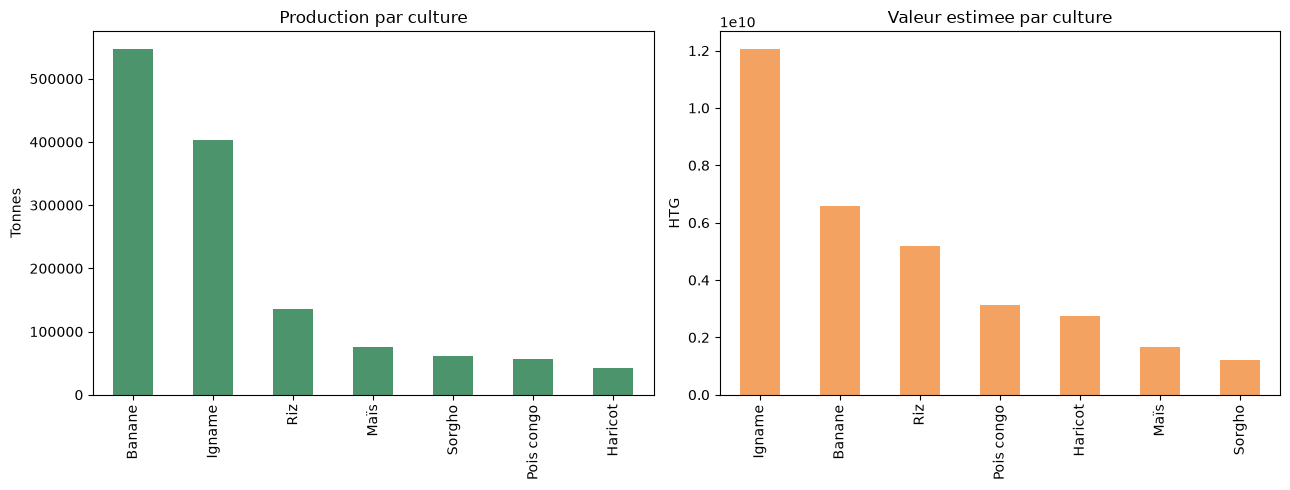

Rang en volume : Banane > Igname > Riz > Maïs > Sorgho > Pois congo > Haricot
Rang en valeur : Igname > Banane > Riz > Pois congo > Haricot > Maïs > Sorgho


In [6]:
classement = (
    complet.groupby("culture", as_index=False)
    .agg(production_t=("production_t", "sum"), valeur_htg=("valeur_htg", "sum"))
    .sort_values("production_t", ascending=False)
)
classement_valeur = classement.sort_values("valeur_htg", ascending=False)
display(classement)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
classement.plot.bar(x="culture", y="production_t", ax=axes[0], legend=False, color="#4c956c")
axes[0].set(title="Production par culture", ylabel="Tonnes", xlabel="")
classement_valeur.plot.bar(x="culture", y="valeur_htg", ax=axes[1], legend=False, color="#f4a261")
axes[1].set(title="Valeur estimee par culture", ylabel="HTG", xlabel="")
plt.tight_layout()
plt.show()

print("Rang en volume :", " > ".join(classement["culture"].tolist()))
print("Rang en valeur :", " > ".join(classement_valeur["culture"].tolist()))

**Ce qu'on en conclut :** La banane domine en volume (547 615 t), tandis que l'igname arrive en tête en valeur estimée (12,07 milliards HTG). Le classement change donc : le prix au kilo de l'igname est nettement supérieur à celui de la banane. Ces montants ne tiennent pas compte des coûts de production ni des variations de prix.

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

,culture,production_t,surface_ha,rendement_t_ha
0,Banane,547615,75857,7.219044
2,Igname,402302,67380,5.970644
5,Riz,136225,48550,2.80587
3,Maïs,75311,71681,1.050641
6,Sorgho,61354,71885,0.853502
4,Pois congo,56626,71919,0.787358
1,Haricot,42323,62024,0.682365


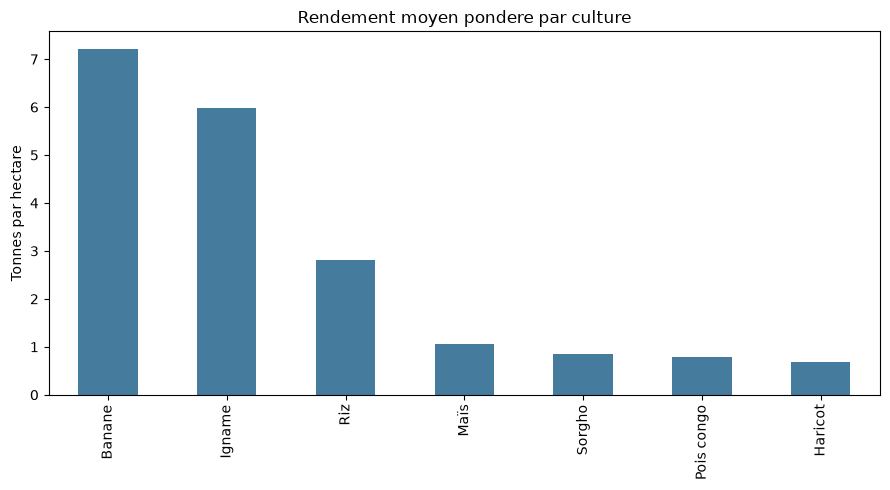

In [7]:
rendements = (
    complet.groupby("culture", as_index=False)
    .agg(production_t=("production_t", "sum"), surface_ha=("surface_ha", "sum"))
)
rendements["rendement_t_ha"] = rendements["production_t"] / rendements["surface_ha"]
rendements = rendements.sort_values("rendement_t_ha", ascending=False)
display(rendements)

fig, ax = plt.subplots(figsize=(9, 5))
rendements.plot.bar(x="culture", y="rendement_t_ha", ax=ax, legend=False, color="#457b9d")
ax.set(title="Rendement moyen pondere par culture", ylabel="Tonnes par hectare", xlabel="")
plt.tight_layout()
plt.show()

culture,Banane,Haricot,Igname,Maïs,Pois congo,Riz,Sorgho
departement,,,,,,,
Artibonite,7.10,0.64,5.79,0.96,0.77,3.80,0.79
Centre,6.64,0.78,5.53,1.20,0.82,NaN,1.08
Grand'Anse,8.66,0.69,8.24,1.11,0.73,NaN,0.91
Nippes,7.21,0.71,5.30,1.05,0.76,NaN,0.85
Nord,9.05,0.70,5.74,1.08,0.74,2.43,0.90
Nord-Est,6.23,0.61,5.32,0.91,0.63,2.12,0.77
Nord-Ouest,6.55,0.60,5.44,0.99,1.01,NaN,0.82
Ouest,6.89,0.63,5.74,1.06,0.80,2.38,0.83
Sud,8.01,0.88,6.56,1.15,0.80,2.68,0.80


,culture,departement,rendement_t_ha
4,Banane,Nord,9.05
18,Haricot,Sud,0.88
22,Igname,Grand'Anse,8.24
31,Maïs,Centre,1.20
46,Pois congo,Nord-Ouest,1.01
50,Riz,Artibonite,3.80
56,Sorgho,Centre,1.08


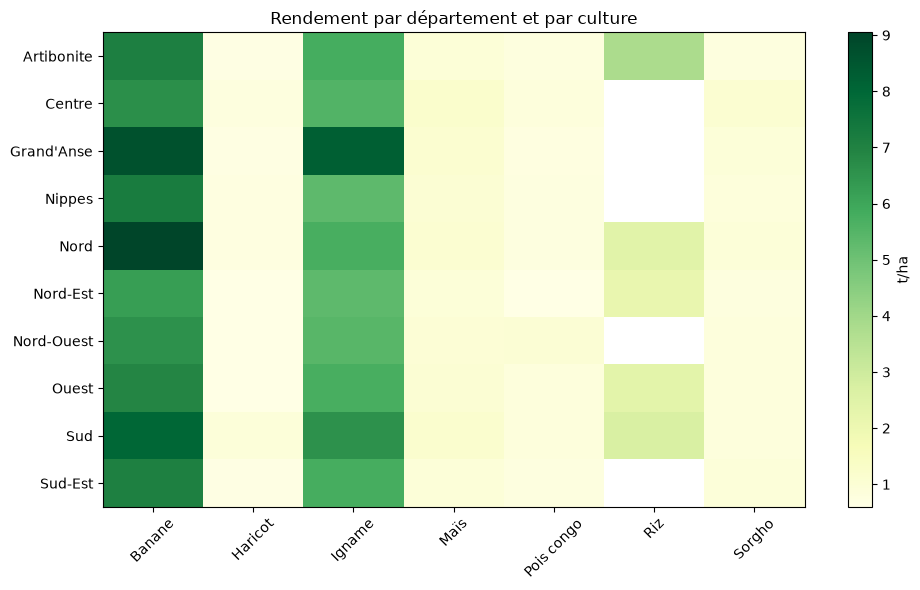

In [8]:
rend_dep = (
    complet.groupby(["culture", "departement"], as_index=False)
    .agg(production_t=("production_t", "sum"), surface_ha=("surface_ha", "sum"))
)
rend_dep["rendement_t_ha"] = (
    rend_dep["production_t"] / rend_dep["surface_ha"]
).astype(float)

tableau = rend_dep.pivot(
    index="departement", columns="culture", values="rendement_t_ha"
).astype(float).round(2)
display(tableau)

meilleurs = rend_dep.loc[
    rend_dep.groupby("culture")["rendement_t_ha"].idxmax(),
    ["culture", "departement", "rendement_t_ha"],
].round(2)
display(meilleurs)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(tableau.to_numpy(dtype=float), aspect="auto", cmap="YlGn")
ax.set_xticks(range(len(tableau.columns)), tableau.columns, rotation=45)
ax.set_yticks(range(len(tableau.index)), tableau.index)
fig.colorbar(im, label="t/ha")
ax.set_title("Rendement par département et par culture")
plt.tight_layout()
plt.show()

Ce qu'on en conclut: La banane affiche le meilleur rendement moyen pondéré (7,22 t/ha), suivie de l'igname (5,97 t/ha) puis du riz (2,81 t/ha). Le haricot présente le rendement le plus faible (0,68 t/ha). Ces valeurs sont des moyennes pondérées par les surfaces, pas des rendements de chaque exploitation.
Par département, la banane atteint son meilleur rendement dans le Nord (9,05 t/ha) et l'igname en Grand'Anse (8,24 t/ha). Pour le riz, c'est l'Artibonite qui est en tête (3,80 t/ha). Le maïs (Centre, 1,20 t/ha), le sorgho (Centre, 1,08 t/ha), le pois congo (Nord-Ouest, 1,01 t/ha) et le haricot (Sud, 0,88 t/ha) restent proches ou sous 1,2 t/ha dans tous les départements. Le riz n'apparaît que dans une partie des départements (30 observations seulement), donc sa comparaison est moins solide.

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

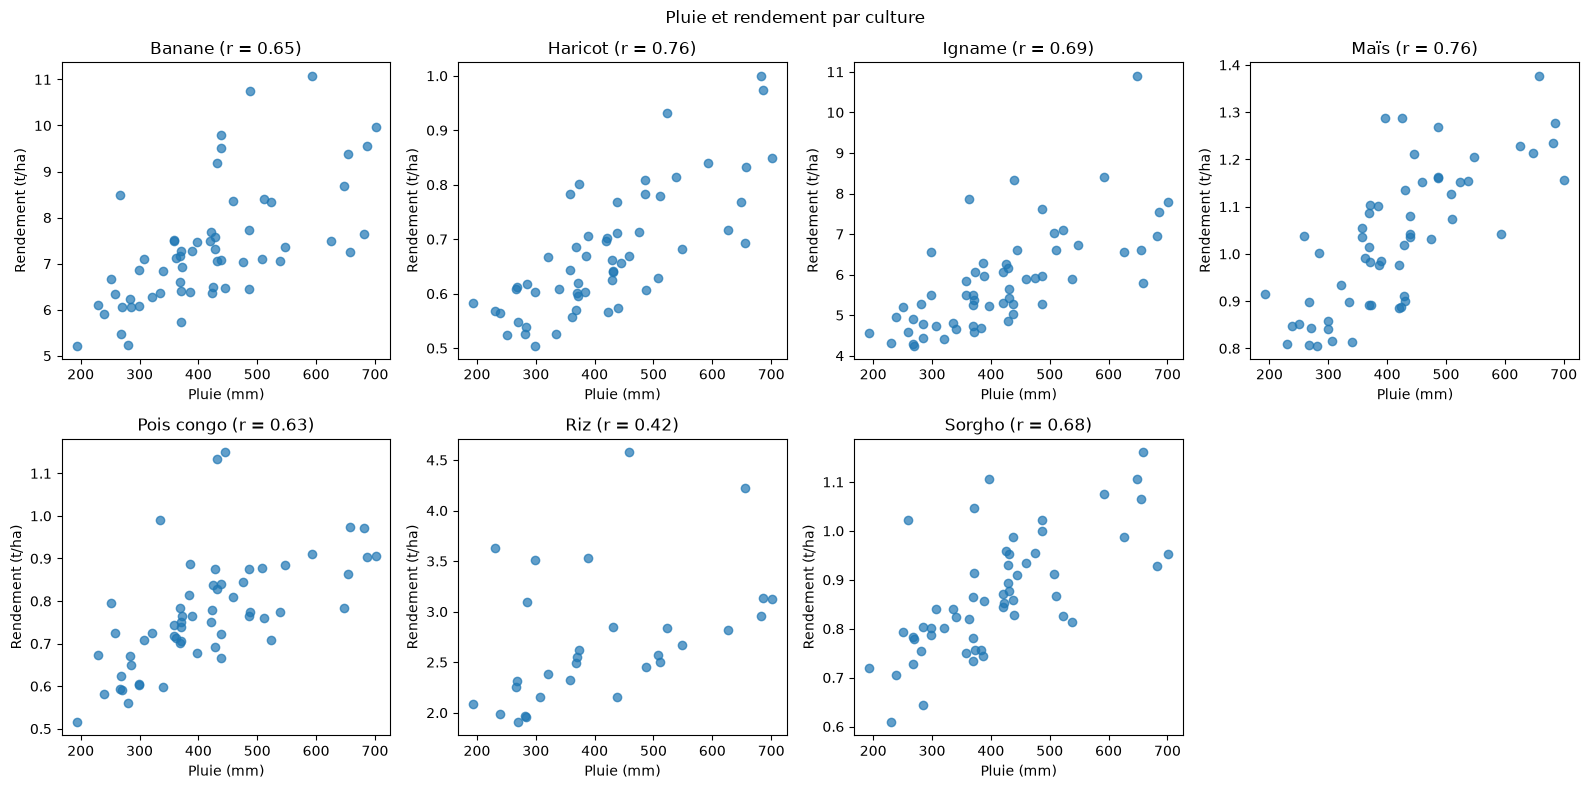

,culture,observations,correlation
1,Haricot,56,0.761049
3,Maïs,58,0.755208
2,Igname,59,0.693539
6,Sorgho,56,0.683731
0,Banane,59,0.645229
4,Pois congo,58,0.626653
5,Riz,30,0.423017


Correlation la plus forte : Haricot
Correlation la plus faible : Riz


In [9]:
correlations_pluie = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (culture, groupe) in zip(axes.flat, complet.groupby("culture", sort=True)):
    ax.scatter(groupe["pluie_mm"], groupe["rendement_t_ha"], alpha=0.7)
    correlation = groupe["pluie_mm"].corr(groupe["rendement_t_ha"])
    correlations_pluie.append({"culture": culture, "observations": len(groupe), "correlation": correlation})
    ax.set(title=f"{culture} (r = {correlation:.2f})", xlabel="Pluie (mm)", ylabel="Rendement (t/ha)")
axes.flat[-1].set_visible(False)
fig.suptitle("Pluie et rendement par culture")
plt.tight_layout()
plt.show()

correlations_pluie = pd.DataFrame(correlations_pluie).sort_values("correlation", ascending=False)
display(correlations_pluie)
print("Correlation la plus forte :", correlations_pluie.iloc[0]["culture"])
print("Correlation la plus faible :", correlations_pluie.iloc[-1]["culture"])

**Ce qu'on en conclut :** Les nuages montrent des associations linéaires positives pour les sept cultures. La corrélation est la plus forte pour le haricot (r = 0,76) et la plus faible pour le riz (r = 0,42). Cela ne prouve pas que la pluie cause les variations de rendement : saison, sols et pratiques agricoles peuvent aussi intervenir.

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

,2023,2024,2025,variation_t,variation_pct
culture,,,,,
Banane,182892,166401,198322,15430,8.436673
Riz,44064,39660,52501,8437,19.14715
Sorgho,20478,16785,24091,3613,17.643325
Pois congo,17484,22271,16871,-613,-3.506063
Haricot,16081,12159,14083,-1998,-12.4246
Maïs,27006,24333,23972,-3034,-11.23454
Igname,161924,130569,109809,-52115,-32.184852


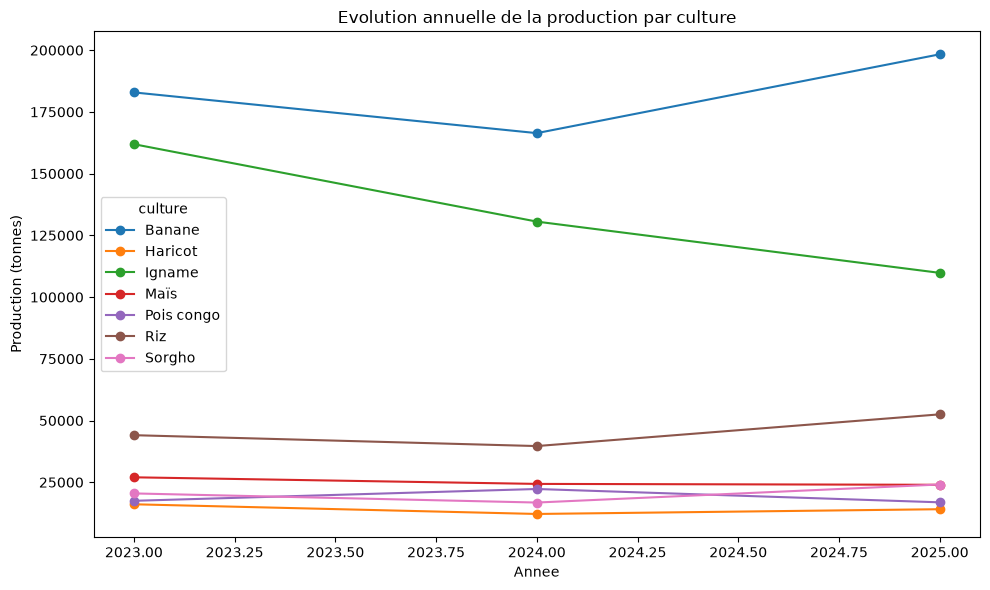

Plus forte progression : Banane (+15,430 t).
Plus fort recul : Igname (-52,115 t).


In [10]:
production_annuelle = complet.pivot_table(
    index="annee", columns="culture", values="production_t", aggfunc="sum"
).sort_index()
variation = pd.DataFrame({
    "production_2023_t": production_annuelle.loc[2023],
    "production_2025_t": production_annuelle.loc[2025],
})
variation["variation_t"] = variation["production_2025_t"] - variation["production_2023_t"]
variation["variation_pct"] = variation["variation_t"] / variation["production_2023_t"] * 100
variation = variation.sort_values("variation_t", ascending=False)
display(production_annuelle.T.join(variation[["variation_t", "variation_pct"]]).sort_values("variation_t", ascending=False))

ax = production_annuelle.plot(marker="o", figsize=(10, 6))
ax.set(title="Evolution annuelle de la production par culture", xlabel="Annee", ylabel="Production (tonnes)")
plt.tight_layout()
plt.show()
print(f"Plus forte progression : {variation.index[0]} ({variation.iloc[0]['variation_t']:+,.0f} t).")
print(f"Plus fort recul : {variation.index[-1]} ({variation.iloc[-1]['variation_t']:+,.0f} t).")

**Ce qu'on en conclut :** Entre 2023 et 2025, la banane enregistre la plus forte hausse de production (+15 430 t), tandis que l'igname connaît le recul le plus marqué (-52 115 t). Le riz et le sorgho progressent également; le maïs, le haricot et le pois congo reculent. Cette comparaison de deux années ne suffit pas à établir une tendance durable.

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

,departement,production_t,population,kg_par_habitant_3_ans
2,Grand'Anse,114384,468301,244.253162
1,Centre,167080,746236,223.896998
8,Sud,155168,774976,200.222975
5,Nord-Est,75030,393967,190.447423
0,Artibonite,269226,1727524,155.845013
3,Nippes,49223,342525,143.706299
9,Sud-Est,80796,632601,127.720317
6,Nord-Ouest,87192,728807,119.636612
4,Nord,118791,1067177,111.313306
7,Ouest,204866,4029705,50.838957


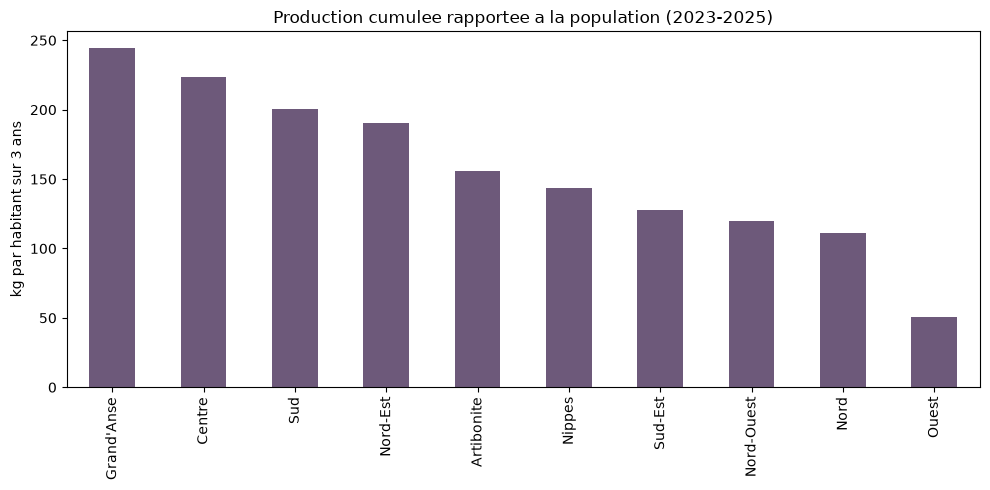

In [11]:
production_habitant = (
    complet.groupby("departement", as_index=False)
    .agg(production_t=("production_t", "sum"), population=("population", "first"))
)
production_habitant["kg_par_habitant_3_ans"] = (
    production_habitant["production_t"] * 1000 / production_habitant["population"]
)
production_habitant = production_habitant.sort_values("kg_par_habitant_3_ans", ascending=False)
display(production_habitant)

fig, ax = plt.subplots(figsize=(10, 5))
production_habitant.plot.bar(x="departement", y="kg_par_habitant_3_ans", ax=ax, legend=False, color="#6d597a")
ax.set(title="Production cumulee rapportee a la population (2023-2025)", ylabel="kg par habitant sur 3 ans", xlabel="")
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :** La Grand'Anse est en tête avec environ 244 kg produits par habitant sur les trois ans, tandis que l'Ouest est dernier avec environ 51 kg. Cet indicateur rapporte la production locale cumulée à la population : il ne représente ni la consommation de chaque habitant ni les échanges entre départements.

## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.

Sur 2023-2025, la banane domine en volume et en rendement, tandis que l'igname génère la plus forte valeur estimée mais recule le plus entre les deux années comparées.
Les corrélations pluie-rendement sont positives dans cet échantillon, sans démontrer de lien de causalité.
La Grand'Anse présente la production cumulée par habitant la plus élevée, et l'Ouest la plus faible.
Les données sont fictives, ne couvrent que trois ans et les prix sont des valeurs unitaires simplifiées.
Pour mieux expliquer les rendements, il faudrait mesurer davantage d'années, la qualité des sols, les pratiques agricoles, l'irrigation et les coûts.